# 01 – Effizienz pro Herzschlag: ein lineares Modell für einen Läufer

**Frage:** Wie viel Strecke bringt ein Herzschlag – und wovon hängt das ab?
Wir leiten eine Kennzahl her, stellen Hypothesen auf, schätzen ein lineares Modell
für einen einzelnen Läufer, prüfen es und machen die Statistik dahinter *anschaulich*.

**Daten:** [running-races-strava](https://github.com/mikeyfera1/running-races-strava) –
42.116 Läufe von 116 Strava-Nutzern (2000–2020), je Lauf nur Summen/Mittelwerte.
Die Daten werden zur Laufzeit aus der Quelle geladen, nicht in diesem Repo gespeichert;
Athleten-IDs werden pseudonymisiert (siehe README).

**Aufbau**
1. Kennzahl definieren
2. Daten laden und filtern
3. Explorativ schauen – *vor* jedem Modell
4. Hypothesen
5. Schätzen
6. Zahlen fühlen: Koeffizient, Standardfehler, t, p, Konfidenzintervall
7. Diagnostik: Ist das Modell vertrauenswürdig?
8. Vorhersagegüte außerhalb der Stichprobe
9. Abgeleitete Größe: Wie viele Höhenmeter entsprechen 1 km?
10. Interpretation, Grenzen, nächste Schritte

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
import statsmodels.api as sm
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor

from laufoekonomie.daten import lade_laeufe, pseudonym

BLAU, ORANGE, GRAU = "#2a78d6", "#eb6834", "#52514e"
plt.rcParams.update({"figure.figsize": (9, 4), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e5e4e0", "axes.axisbelow": True})
pd.set_option("display.precision", 4)
rng = np.random.default_rng(42)   # fester Seed → reproduzierbare Simulationen

## 1. Die Kennzahl

Ein Herzschlag ist die „Währung“, mit der der Körper Strecke kauft. Die
**Effizienz** (engl. *efficiency factor*, EF) ist Strecke pro Herzschlag:

$$
\text{EF} \;=\; \frac{\text{Distanz [m]}}{\text{Herzschläge}}
\;=\; \frac{\text{Distanz [m]}}{\overline{\text{HF}}\;[\tfrac{1}{\text{min}}] \cdot \text{Dauer [min]}}
$$

Ein EF von 1,30 heißt: Jeder Herzschlag bringt 1,30 m. Steigt EF über Monate bei
vergleichbaren Läufen, ist der Läufer aerob effizienter geworden.

Umgestellt ergibt sich die Pace – das macht die Kennzahl praktisch:

$$
\text{Pace [min/km]} \;=\; \frac{1000}{\text{EF}\cdot\overline{\text{HF}}}
$$

**Messschwäche der Datenquelle:** Die Dauer ist die *Gesamtzeit inkl. Pausen*,
die Ø-HF bezieht Strava meist auf die Bewegungszeit. Bei Läufen mit Pausen
werden die Herzschläge also überschätzt, EF fällt zu niedrig aus.

In [2]:
d = lade_laeufe()
ATHLET = "L-f22428"                 # Beispiel-Läufer (Pseudonym, siehe daten.pseudonym)
a = d[(d.athlet == ATHLET)].copy()
print(f"{ATHLET}: {len(a)} Läufe, davon {a.ef.notna().sum()} mit HF und plausibel, "
      f"{a.start.min():%d.%m.%Y} – {a.start.max():%d.%m.%Y}")

L-f22428: 418 Läufe, davon 177 mit HF und plausibel, 16.02.2016 – 31.12.2019


## 2. Filter – und warum

| Filter | Grund |
|---|---|
| plausibel (siehe `daten.py`) | Distanz/Dauer 0, Pace < 2:30 oder > 20 min/km, HF < 40 oder > 220 … |
| HF vorhanden | ohne Puls keine Kennzahl |
| Pace < 9 min/km | schließt Wanderungen/Läufe mit langen Pausen aus – dort misst EF vor allem Pausen |

Jeder Filter ist eine Modellannahme. Wir notieren, wie viele Beobachtungen er kostet.

In [3]:
m = a[a.ef.notna()].copy()
n0 = len(m)
m = m[m.pace < 9].copy()
print(f"mit Kennzahl: {n0}  →  nach Pace-Filter: {len(m)}  (entfernt: {n0 - len(m)})")

m["jahre"] = (m.start - m.start.min()).dt.days / 365.25   # Zeit seit erstem Lauf
m[["km", "dauer_h", "hm_pro_km", "hf", "pace", "ef", "jahre"]].describe().round(2)

mit Kennzahl: 177  →  nach Pace-Filter: 173  (entfernt: 4)


,km,dauer_h,hm_pro_km,hf,pace,ef,jahre
count,173.00,173.00,173.00,173.00,173.00,173.00,173.00
mean,12.90,1.15,7.96,144.72,5.37,1.31,1.43
std,4.74,0.41,9.71,12.16,0.59,0.12,1.08
min,2.56,0.21,0.00,121.60,3.94,0.80,0.00
25%,10.39,0.91,1.89,135.90,5.06,1.25,0.65
50%,12.06,1.08,4.00,142.00,5.31,1.31,1.11
75%,14.77,1.33,13.45,149.40,5.70,1.39,2.03
max,42.41,3.17,74.12,180.80,7.75,1.65,3.83


## 3. Explorativ: erst schauen, dann rechnen

Drei Fragen an die Daten: Hängt EF mit **Dauer**, **Höhenmetern** und der **Zeit**
(Trainingsfortschritt) zusammen? Und: Hängen die erklärenden Variablen *untereinander*
zusammen? Wenn ja, verwischt eine einfache Korrelation die Effekte.

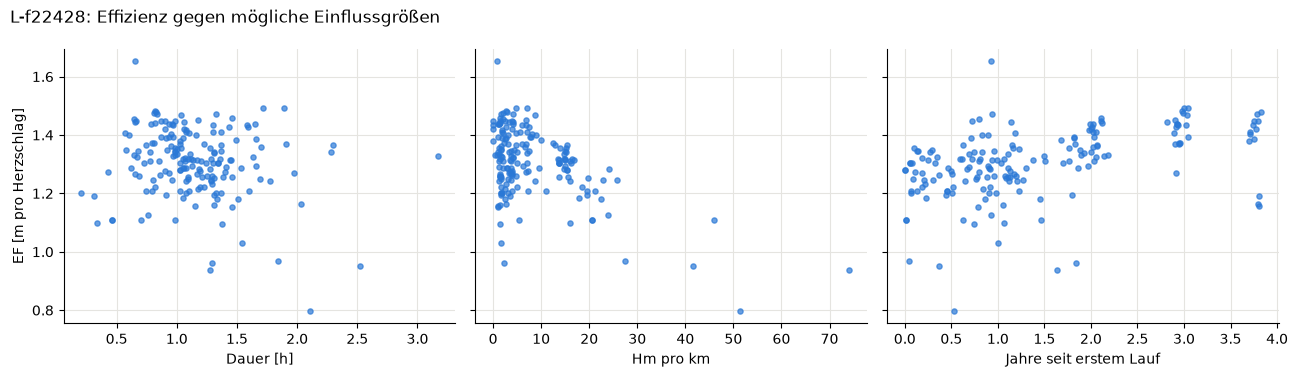

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for axi, (x, lab) in zip(ax, [("dauer_h", "Dauer [h]"), ("hm_pro_km", "Hm pro km"), ("jahre", "Jahre seit erstem Lauf")]):
    axi.scatter(m[x], m.ef, s=14, color=BLAU, alpha=.7)
    axi.set_xlabel(lab)
ax[0].set_ylabel("EF [m pro Herzschlag]")
fig.suptitle(f"{ATHLET}: Effizienz gegen mögliche Einflussgrößen", x=0.01, ha="left")
fig.tight_layout()

In [5]:
# Pearson (linear) und Spearman (nur Rangfolge, robust gegen Ausreißer) nebeneinander
spalten = ["ef", "dauer_h", "hm_pro_km", "jahre"]
pd.concat({"Pearson": m[spalten].corr(), "Spearman": m[spalten].corr(method="spearman")}, axis=1).round(2)

Pearson                         Spearman                        
               ef dauer_h hm_pro_km jahre       ef dauer_h hm_pro_km jahre
ef           1.00   -0.17     -0.52  0.45     1.00   -0.14     -0.26  0.53
dauer_h     -0.17    1.00      0.16  0.12    -0.14    1.00      0.16  0.08
hm_pro_km   -0.52    0.16      1.00 -0.32    -0.26    0.16      1.00 -0.39
jahre        0.45    0.12     -0.32  1.00     0.53    0.08     -0.39  1.00

**Lesehilfe:** Die einfache Korrelation zwischen EF und Dauer ist schwach. Aber Dauer
korreliert mit Hm/km (lange Läufe sind hier hügeliger) – und Hm/km drückt EF stark.
Ob die Dauer *für sich* wirkt, kann erst ein Modell klären, das die anderen
Variablen konstant hält. Das ist der Kern der multiplen Regression
(„ceteris paribus“).

## 4. Hypothesen

| | Hypothese | erwartetes Vorzeichen | Begründung |
|---|---|---|---|
| H1 | Längere Läufe sind weniger effizient | $\beta_1 < 0$ | kardialer Drift: Puls steigt bei gleichem Tempo |
| H2 | Höhenmeter senken die Effizienz | $\beta_2 < 0$ | Hubarbeit kostet Herzschläge ohne Strecke |
| H3 | Effizienz steigt mit Trainingsjahren | $\beta_3 > 0$ | aerobe Anpassung |

Jeweils gegen die Nullhypothese $H_0:\beta_j = 0$ (kein Effekt).

## 5. Das Modell

$$
\text{EF}_i \;=\; \beta_0 \;+\; \beta_1\,\text{Dauer}_i \;+\; \beta_2\,\text{Hm/km}_i \;+\; \beta_3\,\text{Jahre}_i \;+\; \varepsilon_i
$$

$i$ = Lauf, $\varepsilon_i$ = alles, was das Modell nicht erklärt (Tagesform, Wetter,
Pausen, Messfehler). Geschätzt mit der Methode der kleinsten Quadrate (OLS):
wähle $\hat\beta$ so, dass $\sum_i \hat\varepsilon_i^{\,2}$ minimal wird.

In [6]:
FORMEL = "ef ~ dauer_h + hm_pro_km + jahre"
ols = smf.ols(FORMEL, data=m).fit()
print(ols.summary())

                            OLS Regression Results                            
Dep. Variable:                     ef   R-squared:                       0.382
Model:                            OLS   Adj. R-squared:                  0.371
Method:                 Least Squares   F-statistic:                     34.82
Date:                Sun, 08 Nov 2026   Prob (F-statistic):           1.42e-17
Time:                        14:34:02   Log-Likelihood:                 165.42
No. Observations:                 173   AIC:                            -322.8
Df Residuals:                     169   BIC:                            -310.2
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      1.3365      0.023     57.490      0.0

**Was die Tabelle sagt** (bei konstanten anderen Variablen):

- `Intercept` $\hat\beta_0$: EF eines (hypothetischen) 0-Stunden-Laufs ohne Höhenmeter am ersten Tag – Rechengröße, keine reale Situation.
- `dauer_h` $\hat\beta_1$: pro zusätzlicher Stunde ändert sich EF um diesen Betrag.
- `hm_pro_km` $\hat\beta_2$: pro zusätzlichem Höhenmeter je km.
- `jahre` $\hat\beta_3$: pro Trainingsjahr.
- `R-squared`: Anteil der Streuung von EF, den das Modell erklärt.

## 6. Zahlen fühlen

### 6.1 Standardfehler: Wie sehr wackelt ein Koeffizient?

Der Koeffizient ist aus *einer* Stichprobe geschätzt. Hätte der Läufer andere Tage
erwischt, käme ein etwas anderer Wert heraus. Der **Standardfehler** misst genau
dieses Wackeln. Wir machen es sichtbar mit dem **Bootstrap**: 2.000-mal eine
neue Stichprobe gleicher Größe *mit Zurücklegen* aus den Läufen ziehen, jedes Mal
neu schätzen, die Verteilung der Koeffizienten ansehen.

In [7]:
B = 2000
boot = np.empty((B, 4))
for b in range(B):
    s = m.sample(len(m), replace=True, random_state=rng.integers(1e9))
    boot[b] = smf.ols(FORMEL, data=s).fit().params.values
boot = pd.DataFrame(boot, columns=ols.params.index)

vergleich = pd.DataFrame({
    "Koeffizient": ols.params,
    "SE (Formel)": ols.bse,
    "SE (Bootstrap)": boot.std(),
})
vergleich

,Koeffizient,SE (Formel),SE (Bootstrap)
Intercept,1.3365,0.0232,0.0283
dauer_h,-0.0418,0.0181,0.0223
hm_pro_km,-0.0047,0.0008,0.0011
jahre,0.0383,0.0072,0.0077


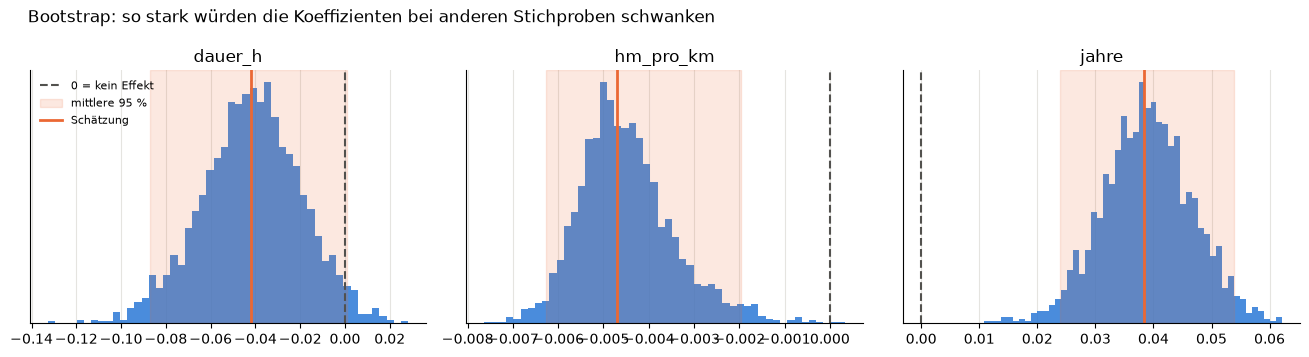

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
for axi, k in zip(ax, ["dauer_h", "hm_pro_km", "jahre"]):
    axi.hist(boot[k], bins=50, color=BLAU, alpha=.85)
    axi.axvline(0, color=GRAU, lw=1.5, ls="--", label="0 = kein Effekt")
    lo, hi = boot[k].quantile([.025, .975])
    axi.axvspan(lo, hi, color=ORANGE, alpha=.15, label="mittlere 95 %")
    axi.axvline(ols.params[k], color=ORANGE, lw=2, label="Schätzung")
    axi.set_title(k); axi.set_yticks([])
ax[0].legend(frameon=False, fontsize=8)
fig.suptitle("Bootstrap: so stark würden die Koeffizienten bei anderen Stichproben schwanken", x=0.01, ha="left")
fig.tight_layout()

### 6.2 t-Wert: Wie viele „Wackelbreiten“ ist der Effekt von null entfernt?

$$
t_j \;=\; \frac{\hat\beta_j - 0}{\text{SE}(\hat\beta_j)}
$$

Faustregel: $|t| > 2$ heißt, der Effekt liegt mehr als zwei Standardfehler von null
entfernt. In den Histogrammen oben: Je weiter die gestrichelte Null außerhalb der
Glocke liegt, desto größer $|t|$.

### 6.3 p-Wert: Wie überraschend wäre das, wenn es *keinen* Effekt gäbe?

Wir simulieren eine Welt, in der $H_0$ stimmt: Wir **mischen die Dauer zufällig**
zwischen den Läufen (Permutation). Dann kann Dauer EF nicht erklären – jeder
geschätzte Effekt ist Zufall. Der p-Wert ist der Anteil dieser Zufallswelten, die
einen mindestens so großen Effekt zeigen wie die echten Daten.

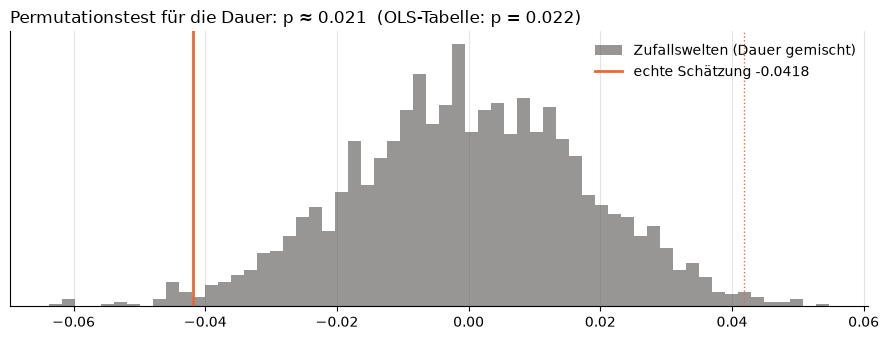

In [9]:
P = 2000
perm = np.empty(P)
for p in range(P):
    s = m.assign(dauer_h=rng.permutation(m.dauer_h.values))
    perm[p] = smf.ols(FORMEL, data=s).fit().params["dauer_h"]
echt = ols.params["dauer_h"]
p_perm = (np.abs(perm) >= abs(echt)).mean()

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.hist(perm, bins=60, color=GRAU, alpha=.6, label="Zufallswelten (Dauer gemischt)")
ax.axvline(echt, color=ORANGE, lw=2, label=f"echte Schätzung {echt:+.4f}")
ax.axvline(-echt, color=ORANGE, lw=1, ls=":")
ax.set_yticks([]); ax.legend(frameon=False)
ax.set_title(f"Permutationstest für die Dauer: p ≈ {p_perm:.3f}  (OLS-Tabelle: p = {ols.pvalues['dauer_h']:.3f})", loc="left")
fig.tight_layout()

**Gefühl dafür:** Liegt die orange Linie mitten im grauen Berg, ist der Effekt mit
Zufall vereinbar (großes p). Liegt sie am Rand, ist Zufall eine unwahrscheinliche
Erklärung (kleines p). *p ist nicht* die Wahrscheinlichkeit, dass $H_0$ wahr ist –
sondern wie selten so ein Ergebnis wäre, *falls* $H_0$ wahr ist.

### 6.4 Konfidenzintervall: der Bereich plausibler Werte

$$
\hat\beta_j \;\pm\; t_{0{,}975;\,n-k}\cdot \text{SE}(\hat\beta_j)
$$

Interpretation über Wiederholung: Würde man das Experiment sehr oft wiederholen und
jedes Mal ein 95-%-Intervall bilden, enthielten 95 % dieser Intervalle den wahren Wert.
Enthält das Intervall die Null nicht, ist der Effekt auf dem 5-%-Niveau signifikant –
dieselbe Aussage wie $p < 0{,}05$, nur in der Einheit des Effekts. Deshalb sind
Intervalle meist nützlicher als p-Werte: Sie zeigen auch, **wie groß** der Effekt
plausiblerweise ist.

In [10]:
ki = pd.concat({
    "Formel 2,5 %": ols.conf_int()[0], "Formel 97,5 %": ols.conf_int()[1],
    "Bootstrap 2,5 %": boot.quantile(.025), "Bootstrap 97,5 %": boot.quantile(.975),
}, axis=1)
ki

,"Formel 2,5 %","Formel 97,5 %","Bootstrap 2,5 %","Bootstrap 97,5 %"
Intercept,1.2906,1.3824,1.2776,1.3897
dauer_h,-0.0776,-0.0061,-0.0869,0.0010
hm_pro_km,-0.0063,-0.0031,-0.0063,-0.0020
jahre,0.0242,0.0525,0.0239,0.0539


### 6.5 In Laufsprache übersetzt

Koeffizienten sind abstrakt. Was bedeuten sie für einen Lauf bei Ø-HF 135?

In [11]:
def pace_str(p):
    return f"{int(p)}:{round((p % 1) * 60):02d}"

szenarien = pd.DataFrame({"dauer_h": [1, 2, 1], "hm_pro_km": [5, 5, 30], "jahre": [3, 3, 3]},
                         index=["1 h flach", "2 h flach", "1 h hügelig"])
vh = ols.get_prediction(szenarien).summary_frame(alpha=.05)
szenarien["EF"] = vh["mean"].values
szenarien["Pace bei HF 135"] = [pace_str(1000 / (e * 135)) for e in szenarien.EF]
szenarien["95-%-Bereich EF (einzelner Lauf)"] = [f"{l:.2f} – {h:.2f}" for l, h in zip(vh.obs_ci_lower, vh.obs_ci_upper)]
szenarien

,dauer_h,hm_pro_km,jahre,EF,Pace bei HF 135,95-%-Bereich EF (einzelner Lauf)
1 h flach,1,5,3,1.3861,5:21,1.20 – 1.57
2 h flach,2,5,3,1.3442,5:31,1.15 – 1.53
1 h hügelig,1,30,3,1.2683,5:50,1.08 – 1.46


Das Vorhersageintervall für einen **einzelnen** Lauf ist breit – Tagesform dominiert.
Für den **Mittelwert** vieler Läufe ist das Modell deutlich genauer
(`mean_ci_lower/upper` in `summary_frame`).

## 7. Diagnostik: Darf man der Tabelle trauen?

OLS-Standardfehler beruhen auf Annahmen. Wir prüfen die wichtigsten.

| Annahme | Test / Blick | Folge bei Verletzung |
|---|---|---|
| Residuen ohne Muster | Residuen gegen Vorhersage | Modell falsch spezifiziert (fehlende Variable, Nichtlinearität) |
| konstante Streuung (Homoskedastizität) | Breusch-Pagan | Standardfehler falsch → robuste SE (HC3) nutzen |
| ~Normalverteilung der Residuen | Q-Q-Plot | bei großem n unkritisch |
| keine starke Multikollinearität | VIF | Koeffizienten instabil, große SE |

Breusch-Pagan: LM = 0.60, p = 0.897   (p < 0,05 → Heteroskedastizität)
VIF: {'dauer_h': np.float64(1.06), 'hm_pro_km': np.float64(1.16), 'jahre': np.float64(1.15)}   (Faustregel: > 5 problematisch)


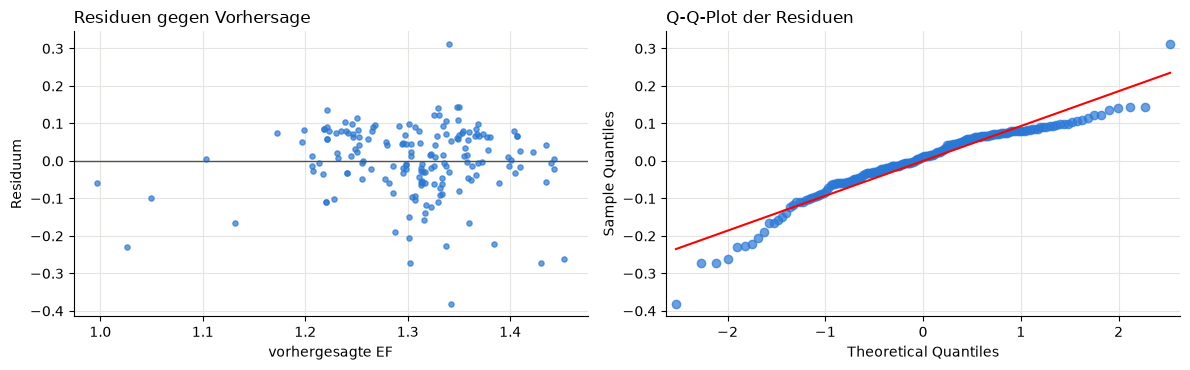

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].scatter(ols.fittedvalues, ols.resid, s=14, color=BLAU, alpha=.7)
ax[0].axhline(0, color=GRAU, lw=1)
ax[0].set_xlabel("vorhergesagte EF"); ax[0].set_ylabel("Residuum")
ax[0].set_title("Residuen gegen Vorhersage", loc="left")
sm.qqplot(ols.resid, line="s", ax=ax[1], markerfacecolor=BLAU, markeredgecolor=BLAU, alpha=.7)
ax[1].set_title("Q-Q-Plot der Residuen", loc="left")
fig.tight_layout()

bp = het_breuschpagan(ols.resid, ols.model.exog)
X = ols.model.exog
vif = {n: variance_inflation_factor(X, i) for i, n in enumerate(ols.model.exog_names) if n != "Intercept"}
print(f"Breusch-Pagan: LM = {bp[0]:.2f}, p = {bp[1]:.3f}   (p < 0,05 → Heteroskedastizität)")
print("VIF:", {k: round(v, 2) for k, v in vif.items()}, "  (Faustregel: > 5 problematisch)")

In [13]:
# Robuste Standardfehler (HC3) zum Vergleich – ändern die Schlussfolgerungen sich?
rob = ols.get_robustcov_results(cov_type="HC3")
pd.DataFrame({"SE OLS": ols.bse, "SE HC3": rob.bse, "p OLS": ols.pvalues, "p HC3": rob.pvalues}, index=ols.params.index)

,SE OLS,SE HC3,p OLS,p HC3
Intercept,0.0232,0.0284,7.1387e-113,3.8979e-99
dauer_h,0.0181,0.0224,2.2037e-02,6.3442e-02
hm_pro_km,0.0008,0.0010,1.8788e-08,5.7621e-06
jahre,0.0072,0.0079,2.6941e-07,2.6602e-06


**Beobachtung:** Breusch-Pagan findet keine Heteroskedastizität, trotzdem sind die
HC3- und die Bootstrap-Standardfehler für `dauer_h` gut 20 % größer als die
OLS-Standardfehler. HC3 gewichtet Beobachtungen mit großem Hebel stärker. Das deutet auf
**einzelne einflussreiche Läufe** hin, etwa sehr lange Läufe, die in der Dauer weit vom Rest
entfernt liegen. Für die Dauer kippt dadurch die Signifikanz (p von 0,02 auf etwa 0,06).

## 8. Vorhersagegüte außerhalb der Stichprobe

$R^2$ misst, wie gut das Modell die Daten beschreibt, *an denen es geschätzt wurde*.
Ehrlicher ist ein Test auf Daten, die es nie gesehen hat: Schätzen auf 2016–2018,
vorhersagen für 2019. Vergleichsmaßstab ist die naive Prognose „Mittelwert der
Trainingsdaten“.

$$
\text{RMSE} = \sqrt{\tfrac{1}{n}\textstyle\sum_i (\text{EF}_i - \widehat{\text{EF}}_i)^2}
$$

In [14]:
train, test = m[m.start < "2019-01-01"], m[m.start >= "2019-01-01"]
fit_tr = smf.ols(FORMEL, data=train).fit()
rmse = lambda e: float(np.sqrt(np.mean(np.square(e))))
print(f"Training n = {len(train)}, Test n = {len(test)}")
print(f"RMSE Modell:        {rmse(fit_tr.predict(test) - test.ef):.3f}")
print(f"RMSE Mittelwert:    {rmse(train.ef.mean() - test.ef):.3f}")

Training n = 142, Test n = 31
RMSE Modell:        0.101
RMSE Mittelwert:    0.144


## 9. Abgeleitete Größe: Wie viele Höhenmeter entsprechen 1 km flach?

Aus $\beta_2$ lässt sich ein **Höhenmeter-Äquivalent** ableiten. Kostet 1 Hm so viele
Herzschläge wie $c$ Meter flach, gilt näherungsweise
$c = -\beta_2 \cdot 1000 / \overline{\text{EF}}_0$ und damit

$$
\text{Hm-Äquivalent für 1 km} \;=\; \frac{1000}{c}
$$

Das ist eine *nichtlineare* Funktion der Koeffizienten – ihr Konfidenzintervall
steht nicht in der Tabelle. Der Bootstrap liefert es ohne weitere Formeln.
Zum Vergleich: Die ITRA-Faustregel setzt 100 Hm = 1 km.

In [15]:
def hm_aequivalent(params, daten):
    ef0 = params["Intercept"] + params["dauer_h"] * daten.dauer_h.mean() + params["jahre"] * daten.jahre.mean()
    c = -params["hm_pro_km"] * 1000 / ef0
    return 1000 / c

punkt = hm_aequivalent(ols.params, m)
verteilung = boot.apply(lambda r: hm_aequivalent(r, m), axis=1)
lo, hi = verteilung.quantile([.025, .975])
print(f"1 km flach ≈ {punkt:.0f} Hm   (95-%-Bootstrap-Intervall {lo:.0f} – {hi:.0f})   vs. ITRA 100 Hm")

1 km flach ≈ 285 Hm   (95-%-Bootstrap-Intervall 216 – 667)   vs. ITRA 100 Hm


## 10. Interpretation, Grenzen, nächste Schritte

**Ergebnis für diesen Läufer** (Zahlen siehe oben):
- **H1 (Dauer):** Die Punktschätzung ist negativ (etwa −3 % EF pro Stunde) und mit den
  Standard-OLS-Fehlern signifikant (p ≈ 0,02). Mit **robusten Standardfehlern (HC3)**
  steigt p aber auf ≈ 0,06, und das **Bootstrap-Intervall enthält die Null**. Der Effekt
  ist also *nicht gesichert*. Er hängt an wenigen einflussreichen Läufen, zum Beispiel einem
  Marathon über 3,2 h. Lehre: Ein einzelner p-Wert aus der Standardtabelle reicht nicht, man sollte ihn
  mit robusten Verfahren gegenprüfen.
- **H2 (Höhenmeter):** deutlich negativ. Das Hm-Äquivalent liegt weit über der
  ITRA-Regel: Für diesen Straßenläufer kostet ein Höhenmeter weniger, als ITRA unterstellt.
- **H3 (Trend):** positiv – der Läufer wurde über die Jahre effizienter.
- Das Modell erklärt gut ein Drittel der Streuung und schlägt die naive Prognose
  außerhalb der Stichprobe.

**Grenzen**
- Ein Läufer, Beobachtungsdaten: Zusammenhänge, keine Kausalität.
- Gesamtzeit inkl. Pausen verzerrt EF nach unten (Abschnitt 1).
- Ein linearer Trend kann nicht beliebig fortgeschrieben werden.
- Läufe sind zeitlich geordnet – Residuen benachbarter Tage könnten korreliert sein
  (noch nicht geprüft: Durbin-Watson steht in der Tabelle).

**Nächste Schritte** (siehe README, Roadmap)
- Einflussreiche Beobachtungen finden (Cook's Distance, Leverage) und H1 ohne sie prüfen
- Dasselbe Modell für alle Läufer → Verteilung der Koeffizienten (Notebook 02)
- Panel-Modell: gemeinsame Effekte plus läuferspezifische Achsenabschnitte (fixed effects)
- Nichtlinearitäten (Dauer², Interaktion Dauer × Hm) prüfen